**Author**: JW Debelius (justine.debelius@jhu.edu)<br>
**Project**: 017-Arg<br>
**Enviroment**: <br>
**Creation Date**: July 2021<br>
**Update Date**: November 2025

This notebook takes the alpha diversity trajectories and models they using a perturbation-recovery model. Our perturbation-recovery model is essentially a non-linear fit that assumes the data looks like a 1/x curve (two aspmyotoes at 0 and the intercept); see traces below.

Our model is defined as

$y(t) = mt^{-1} + b$

where $y(t)$ is the percentage of baseline diversity $t$ days after treatment, $m$ is rate at which diveristy recovers, and $b$ is the new steady state to which diveristy recovers.

For this model to work, we assume that 

1. Without intervention, the diversity would remain at approximately steady state over the study period.<br>While we see changes in the microbiome with age, this is generally over decades.
3. Treatment is short compared to the length of follow up, and therefore we can assume that threatment is an instanteous or close to instantenous effect.<br>This is a somewhat tenous assumption, but not a terrible one as 5 days is short in a 365 day timeline.
4. The treatment does not have lasting effects on the rate of bacterial growth, meaning that an delayed recovery is assumed to be due to a greater perturbation (more ground to recover) rather than a slowing of growth.<br>This is also a hard assumption to test. Most of hte anitbiotic teratments here are excreted within 24 hours of treatment, so the mechanism should not be due to sustained antibiotic exposure. However, its possible that antibiotics might induce genomic changes leading to spore formation and that delay recovery.

In [1]:
import itertools as it
import re
import os
import warnings
warnings.simplefilter(category=FutureWarning, action='ignore')

import numpy as np
import pandas as pd
import scipy
from scipy.stats import studentized_range as q_dist
import seaborn as sn
import skbio
import patsy
import statsmodels.formula.api as smf
import statsmodels.api as sms

from matplotlib import rcParams
import matplotlib.pyplot as plt
from matplotlib import ticker

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.longitudinal.actions as q2_longitudinal

import scripts.alpha_plots as ap
from scripts.extract_fits import (extract_period_fits,
                                  extract_abxbl_fit,
                                  extract_recovery_fits,
                                  build_tidy_str,
                                  find_abx,
                                  _check_var,
                                 )

from IPython.display import HTML

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
hide_axes = dict(left=False, labelleft=False,
                 right=False, labelright=False,
                 length=0,
                 labelsize=0)

In [3]:
%matplotlib inline
rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42
np.set_printoptions(precision=5)


In [4]:
abx_order = ['untreated', 'nitrofurantoin', 'pivmecillinam',
             'co-trimoxazole', 'ceftibuten', 'ciprofloxacin']
colors = ['#969696', '#009E73','#9D654C', 
          '#4E7705', '#098BD9',  '#CC79A7']
spectrum_order = ['untreated', 'narrow', 'broad']
alpha_metrics = ['observed_features', 'shannon', 'simpson']
abx_names = {str(i): abx for i, abx in enumerate(abx_order)}
abx_colors = {str(i): color for i, color in enumerate(colors)}

colors_lite = ['#B9B9B9', '#54BEA2', '#BE9888', '#8AA458', '#5BB1E5', '#DEA5C5']
abx_colors_l = {str(i): c for i,c in enumerate(colors_lite)}

In [5]:
clean_metrics = {'observed_features': 'Observed Species',
                 'obs_feat': 'Observed Species',
                 'unweighted_unifrac': 'unweighted\nUniFrac',
                 'weighted_unifrac': 'weighted\nUniFrac',
                 'braycurtis': 'Bray Curtis',
                 'rpca': 'rPCA\nAitchison',
                 'phylo_rpca': 'phylo rPCA\nAitchison'
                 }


# Data

## Metadata

In [6]:
meta_all = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta_all.set_index('sample-id', inplace=True)
meta_all[['age', 'days_since_intervention', 'gtdb_depth']] = \
    meta_all[['age', 'days_since_intervention', 'gtdb_depth']].astype(float)

meta = meta_all[['host_subject_id', 'timepoint', 'days_since_intervention',
             'abx_code2', 'age', 'sex', 'vegetarian', 'extraction_no', 'after_travel_na_eu']].copy()

## Alpha Diversity

In [7]:
alpha_dir = 'final-data/04.alpha-diveristy'
alpha_metrics = ['observed_features', 'shannon', 'simpson']
alpha_q2 = {
    metric: Artifact.load(f'{alpha_dir}/{metric}_1M_avg.qza')
    for metric in alpha_metrics
    }
meta_a = pd.DataFrame({metric: art.view(pd.Series) 
                       for metric, art in alpha_q2.items()})
meta_a[['host_subject_id', 'timepoint']] = meta[['host_subject_id', 'timepoint']]
meta_a.sort_values(['host_subject_id', 'timepoint'], ascending=True, inplace=True)
meta_a0 = meta_a.groupby('host_subject_id').first()[alpha_metrics]
alpha0 = meta_a0.loc[meta_a['host_subject_id'], alpha_metrics]
alpha0.index = meta_a.index

In [8]:
a_traces_q2 = {
    metric: Artifact.load(f'{alpha_dir}/{metric}_1M_avg_from_baseline.qza')
    for metric in np.hstack([alpha_metrics, 'depth'])
    }
a_traces = pd.DataFrame(
    {metric: art.view(pd.Series) for metric, art in a_traces_q2.items()
     if metric in alpha_metrics}
)

## Combined data

In [9]:
meta_t = pd.concat(
    axis=1, 
    objs=[meta,
          a_traces_q2['depth'].view(pd.Series).to_frame().rename(columns={'Difference': 'depth_d'}) / 1e5,
          (a_traces / alpha0 * 100), 
          alpha0.add_suffix('_0'),
          (alpha0 < meta_a0.median()).add_suffix('_0_cat').replace({True: 'lo', False: 'hi'})
         ]
    )

meta_t.replace({metric: {np.nan: 0} for metric in alpha_metrics},
              inplace=True)
meta_t.sort_values(['abx_code2', 'host_subject_id', 'timepoint'],
                   ascending=True, inplace=True)
meta_t['first_extraction'] = \
    meta_t['host_subject_id'].replace(meta_t.groupby('host_subject_id')['extraction_no'].first())
meta_t['extr_not0'] = (meta_t['extraction_no'] != meta_t['first_extraction']) * 1
meta_t['days_inv'] = 30 / meta_t['days_since_intervention']
meta_t['abx_code2'] = meta_t['abx_code2'].astype(int)
meta_t['period'] = (meta_t['timepoint'].astype(float) > 0) * 1 + \
    (meta_t['timepoint'].astype(float) > 3) * 1

# Visualization

In [10]:
trace_w = meta_t.pivot(index=['abx_code2', 'host_subject_id'],
                       columns='timepoint',
                       values=alpha_metrics)
trace_summary = \
    meta_t.groupby(['abx_code2', 'timepoint'])[alpha_metrics].describe()
trace_summary.columns.set_names(['metric', 'statistic'], inplace=True)
trace_summary = trace_summary.unstack().unstack().reset_index()
trace_summary.rename(columns={0: 'value'}, inplace=True)
trace_summary['abx_code2'] = trace_summary['abx_code2'].astype(int)
trace_summary = trace_summary.pivot(
    index=['metric', 'abx_code2', 'timepoint'],
    columns='statistic',
    values='value',
    )
trace_summary['t'] = scipy.stats.t.ppf(0.975, df=trace_summary['count'] - 1)
trace_summary['sem'] = trace_summary['std'] / np.sqrt(trace_summary['count'] - 1)
trace_summary['ci'] = trace_summary['sem'] * trace_summary['t']

trace_summary = trace_summary.unstack()


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


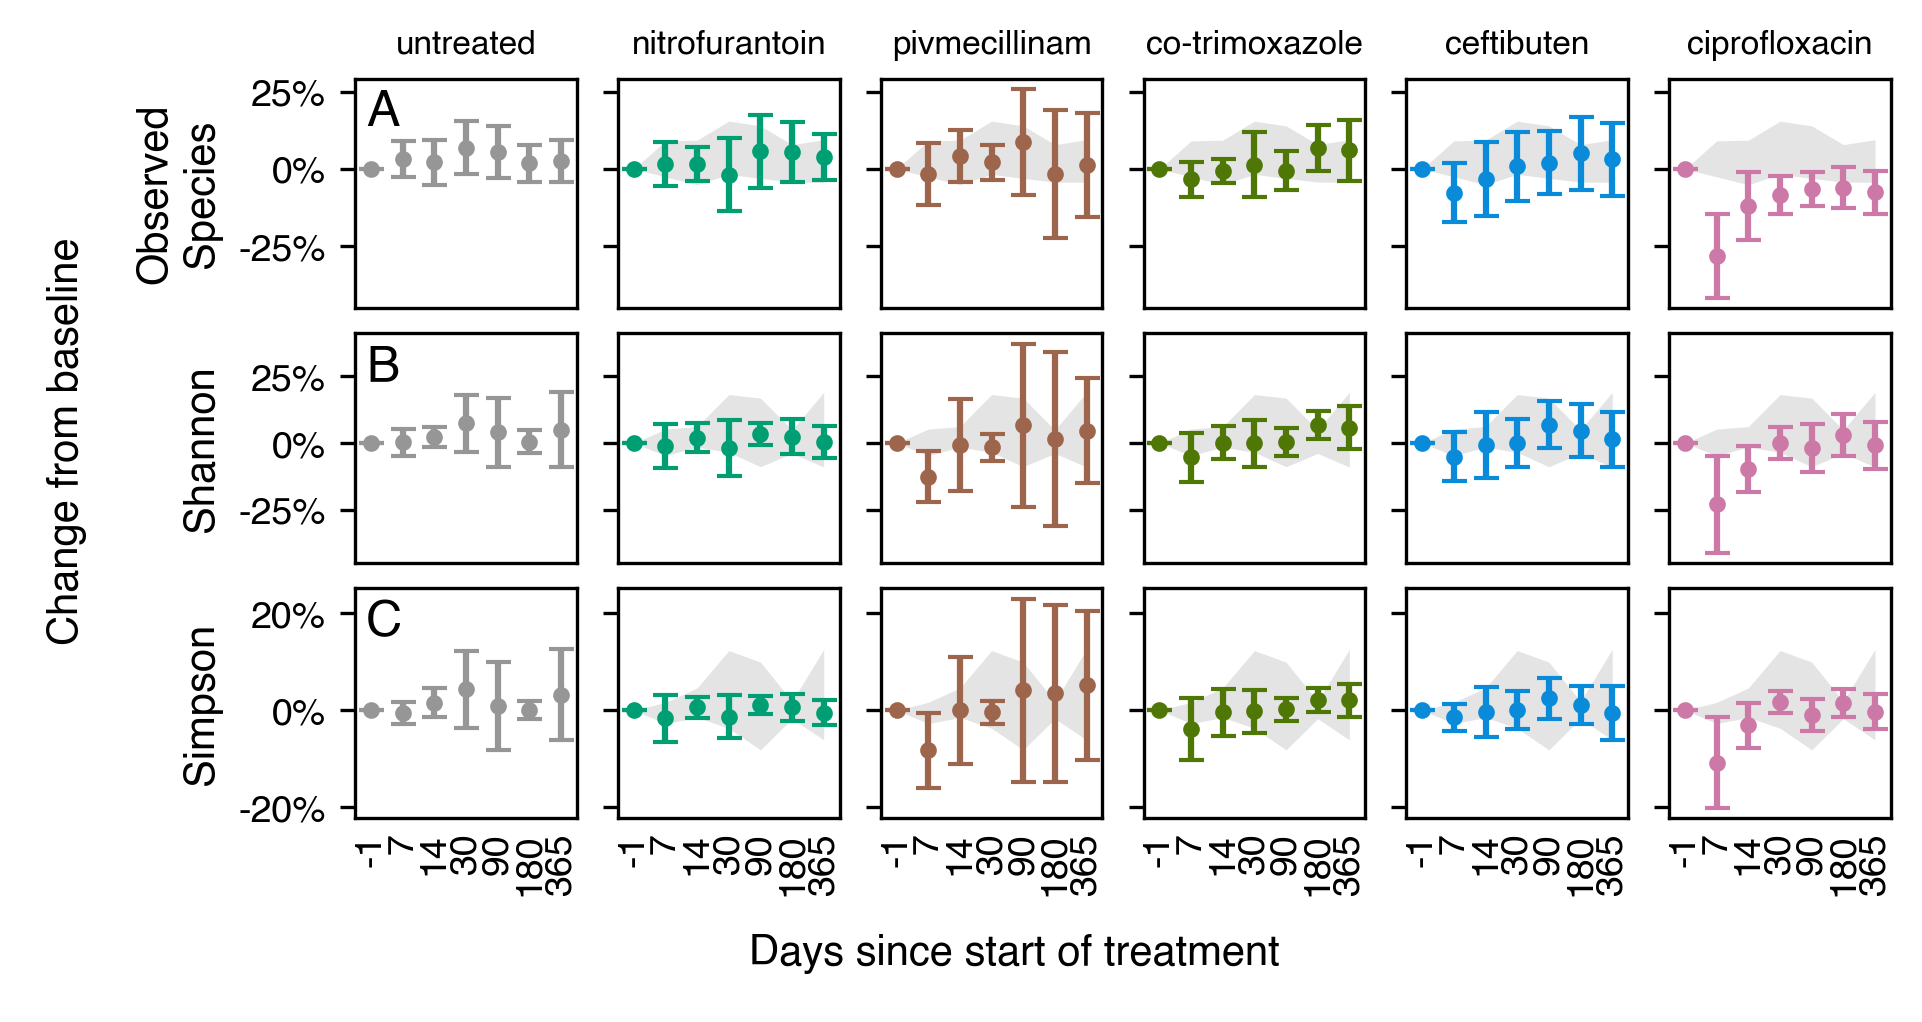

In [11]:
fig_all = plt.figure(dpi=300, constrained_layout=True, figsize=(6.25, 3.25), facecolor='None')
[[figya, figa], [_, figx]] = fig_all.subfigures(2, 2, 
                                              width_ratios=[0.25, 6], 
                                              height_ratios=[3, 0.25], 
                                             facecolor='None')
gsa = figa.add_gridspec(3, 6)
for row, metric in enumerate(alpha_metrics):
    metric_clean = clean_metrics.get(metric, metric.title()).replace(' ', '\n')
    msummary_df = trace_summary.xs(metric, level='metric')
    for abx, trace_df in trace_w[metric].groupby('abx_code2'):
        if abx == 0:
            axa = figa.add_subplot(gsa[row, abx])
            axa.set_ylabel(metric_clean, size=10)
            axra = axa
        else:
            axa = figa.add_subplot(gsa[row, abx], sharex=axa, sharey=axa)
        if row == 0:
            axa.set_title(abx_order[abx], size=8)
        ap._plot_forest_square(axa, abx, msummary_df)
        ap._format_alpha_axes(axa, abx, row == 2)
    axra.text(x=axra.get_xlim()[0] + 0.05 * np.diff(axra.get_xlim()), 
              y=axra.get_ylim()[1] - 0.05 * np.diff(axra.get_ylim()), 
              s='ABC'[row], 
              size=12, ha='left', va='top')
ap._add_labelfig(figya, 'Change from baseline', rotation=90)
ap._add_labelfig(figx, 'Days since start of treatment', rotation=0)

fig_all.savefig('output/figures/fig_s6_alpha_trace.png', dpi=600, facecolor='None')
fig_all.savefig('output/figures/fig_s6_alpha_trace.pdf', dpi=600, facecolor='None')


**Figure S6. Change in alpha diversity over time among participants.** Change in alpha diversity (mean ± 95% confidence interval) following treatment. Gray shading indicates 95% CI for the untreated group. (D-F) Traces showing within-individual changes in alpha diversity over time. The main line shows the mean and the shaded area is the 95% confidence interval. Traces are shown for metric with ascending Hill Numbers: (A) Observed Species, (B) Shannon Diversity, and (C) Simpson Diversity. There is no modeling shown.

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or axes decorations smaller.
  func(*args, **kwargs)
/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


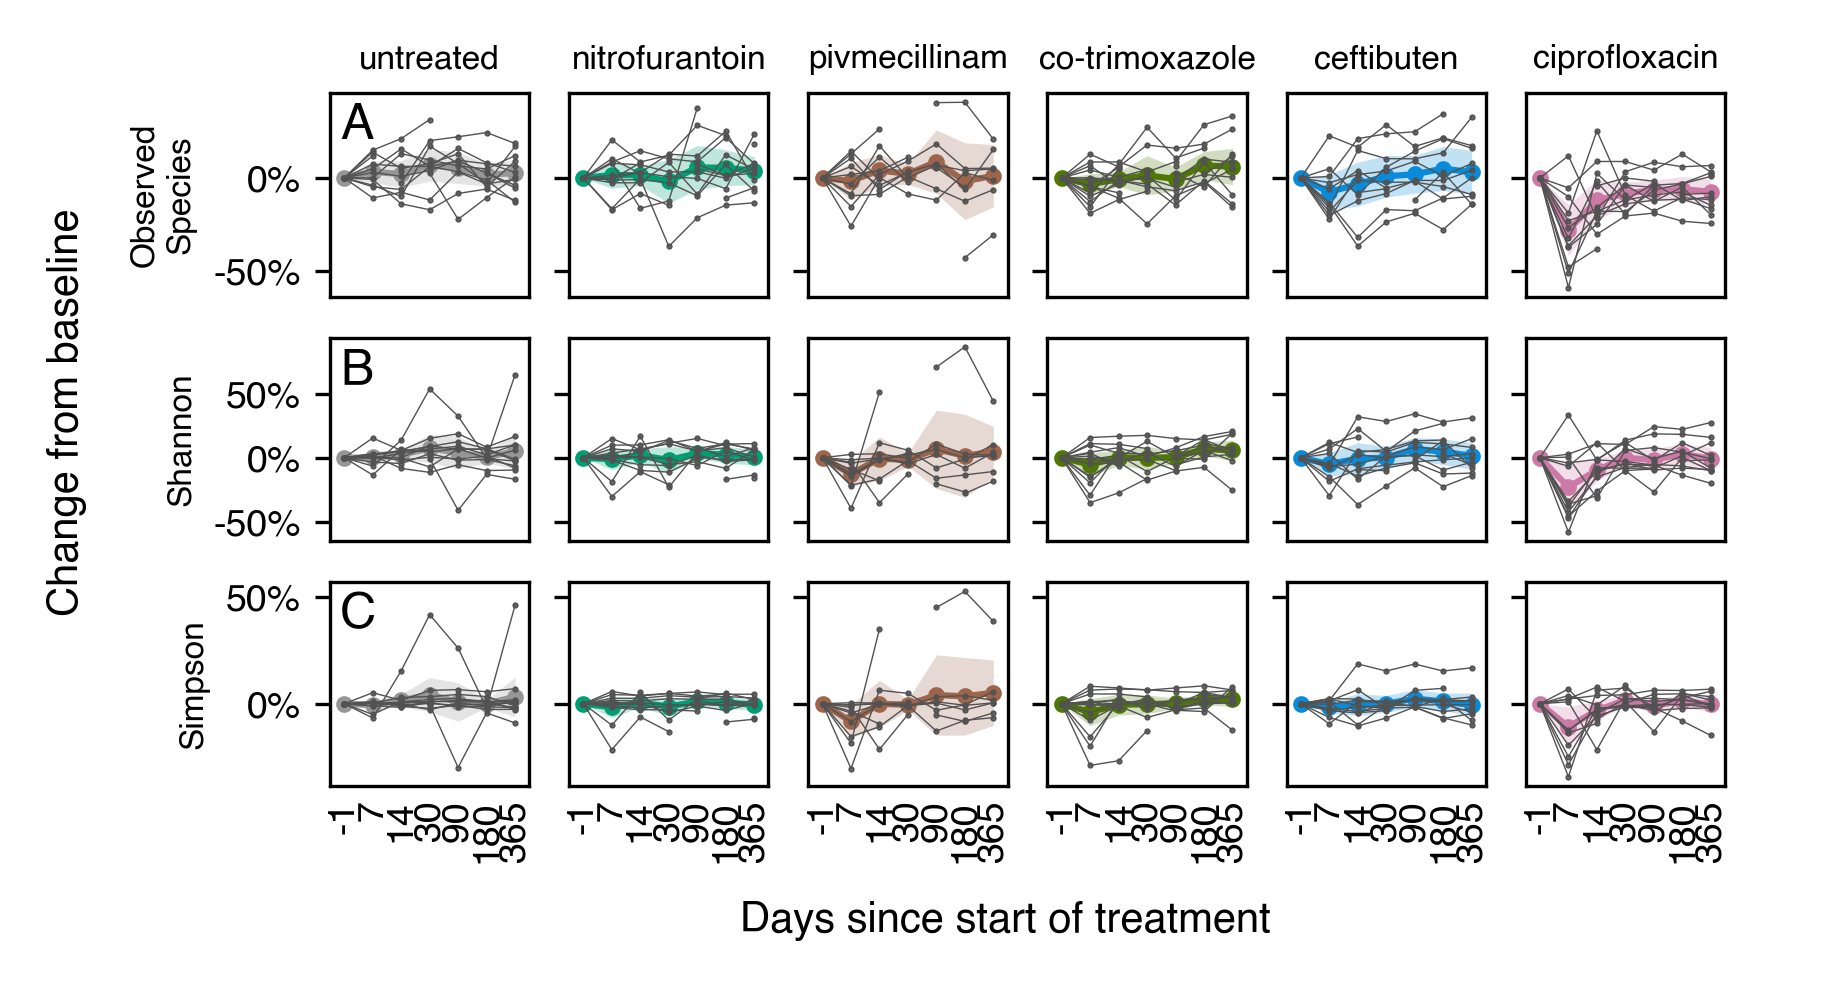

In [12]:
fig_all = plt.figure(dpi=300, constrained_layout=True, figsize=(6.25, 3.25), facecolor='None')
[[figyb, figb], [_, figx]] = fig_all.subfigures(2, 2, 
                                              width_ratios=[0.25, 6], 
                                              height_ratios=[3, 0.25], 
                                             facecolor='None')
gsb = figyb.add_gridspec(3, 6)
for row, metric in enumerate(alpha_metrics):
    metric_clean = clean_metrics.get(metric, metric.title()).replace(' ', '\n')
    msummary_df = trace_summary.xs(metric, level='metric')
    for abx, trace_df in trace_w[metric].groupby('abx_code2'):
        if abx == 0:
            axb = figb.add_subplot(gsb[row, abx])
            axb.set_ylabel(metric_clean, size=8)
            
            axrb = axb
        else:
            axb = figb.add_subplot(gsb[row, abx], sharex=axb, sharey=axb)
        if row == 0:
            axb.set_title(abx_order[abx], size=8)
        ap._plot_trace_square(axb, abx, msummary_df, trace_df, scale=0)
        ap._format_alpha_axes(axb, abx, row == 2) 
    axrb.text(x=axrb.get_xlim()[0] + 0.05 * np.diff(axrb.get_xlim()), 
              y=axrb.get_ylim()[1] - 0.05 * np.diff(axrb.get_ylim()), 
              s='ABC'[row], 
              size=12, ha='left', va='top')
ap._add_labelfig(figyb, 'Change from baseline', rotation=90)
ap._add_labelfig(figx, 'Days since start of treatment', rotation=0)


**Figure R1. Within individual change in alpha diversity following antibiotic treatment.** Traces showing within-individual changes in alpha diversity over time. The main line shows the mean and the shaded area is the 95% confidence interval. Alpha diversity from each participant is shown as a connected trace. Traces are shown for metric with ascending Hill Numbers: (A) Observed Species, (B) Shannon Diversity, and (C) Simpson Diversity.

# Modeling

In [13]:
meta_r = meta_t.loc[~meta_t['timepoint'].isin(['0.0'])].copy()

## Adjustments

In [14]:
ref_eqs = {
    'crude': 'depth_d',
    'model 1': 'depth_d + C(extraction_no)',
    'model 2': ('depth_d + C(extraction_no) + after_travel_na_eu'),
    'model 3': ('depth_d + C(extraction_no) + after_travel_na_eu + age + sex + vegetarian'),
}

In [15]:
fit_untreat = {
    (metric, model, rs_slope, '0'): smf.mixedlm(
        f'{metric} ~ C(abx_code2)*days_inv + {ref_eq}',
        data=meta_r,
        re_formula=re_formula,
        groups='host_subject_id'
        ).fit()
    for model, ref_eq in ref_eqs.items()
    for rs_slope, re_formula in enumerate(['~1', '~days_inv'])
    for metric in alpha_metrics
    }
fit_unt_params = \
    pd.concat([extract_recovery_fits(fit_, *keys) 
               for keys, fit_ in fit_untreat.items()])
fit_unt_params.set_index(['metric', 'slope', 'model', 'rs_slope', 
                          'ref_value', 'abx_code'],
                         inplace=True)

We're also going to do some post-hoc testing using the emmeans package in R

In [16]:
posthoc_dir = 'final-data/04.alpha-diveristy/post-hoc-fits'
os.makedirs(posthoc_dir, exist_ok=True)
meta_r.to_csv(f'{posthoc_dir}/alpha_trace.tsv', sep='\t')

In [17]:
%%bash
Rscript scripts/emmeans_posthoc/alpha_lmer_posthoc.R

There were 42 warnings (use warnings() to see them)
There were 42 warnings (use warnings() to see them)


In [18]:
fit_unt_exp = \
    pd.read_csv(f'{posthoc_dir}/alpha_expanded_est.tsv',
                sep='\t', dtype=str)
fit_unt_exp['slope'] = fit_unt_exp['kind'].isin(['m']) * 1
fit_unt_exp.set_index(['metric', 'model', 'rs', 'slope', 'abx_code2'], 
                      inplace=True)
fit_unt_exp.drop(columns=['kind'], inplace=True)
fit_unt_exp.rename(columns={'lower.CL': 'ci_lo', 'upper.CL': 'ci_hi'},
                   inplace=True)
fit_unt_exp = fit_unt_exp.astype(float)
fit_unt_exp['width'] = fit_unt_exp['ci_hi'] - fit_unt_exp['beta']


## Alpha Plots

In [19]:
days = np.hstack([np.arange(1, 15, 1),
                  np.arange(15, 30, 3),
                  np.arange(30, 90, 15),
                  np.arange(90, 400, 30),
                 ])
predicted_alpha = ap.build_timing_grid(days, fit_unt_exp)

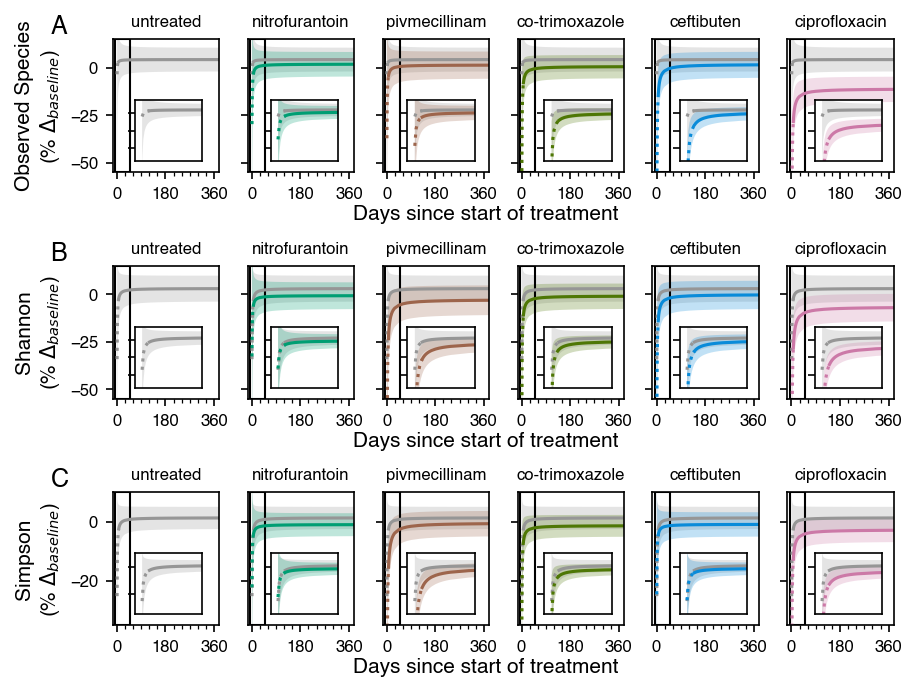

In [20]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6, 4.5), facecolor='None')
figs = fig.subfigures(3, 1, facecolor='None')
for i, (fig_, (metric, df)) in enumerate(zip(*(figs, predicted_alpha.groupby('metric', sort=False)))):
    sub_data = df.reset_index(level='metric', drop=True)
    sub_data = sub_data.xs('model2', level='model')
    sub_data = sub_data.xs('re', level='rs')
    ap.plot_alpha_curve_row(fig_, metric, sub_data, label=['A', 'B', 'C'][i])

# Modeled data

We'll fit the models using a random intercept (the original fit) and random slope, and adjust for difference sets of confounders, and then we'll extract the parameters and data for plotting.

I want to look at two models here: the main model and a baseline adjsuted model with a random intercept.

In [21]:
sub_re = fit_unt_params.copy().xs(0, level='rs_slope')
sub_re.drop(index=['crude', 'model 1'], level='model', inplace=True)
sub_re.reset_index(level=['ref_value'], drop=True, inplace=True)
sub_re.reset_index(inplace=True)

sub_re['width'] = sub_re['ci_hi'] - sub_re['params']
sub_re['tidy'] = sub_re.apply(
    lambda x: '{params:1.2f} ({ci_lo:1.2f}, {ci_hi:1.2f})'.format(**x), axis=1)
sub_re['tidy'] = \
    sub_re['tidy'].mask(sub_re['abx_code'].isin(['0', 0]), '0 (ref)')
sub_re['params'] = sub_re['params'].mask(sub_re['abx_code'].isin(['0', 0]), 0)
sub_re['width'] = sub_re['width'].mask(sub_re['abx_code'].isin(['0', 0]), np.nan)
sub_re['p_value'] = sub_re['p_value'].mask(sub_re['abx_code'].isin(['0', 0]), 1)


sub_re['y'] = 5 - sub_re['abx_code'].astype(int) + \
    sub_re['model'].replace({'model 2': 1, 'model 3': -1}) * 0.2
sub_re['color'] = sub_re['abx_code'].replace(abx_colors)
sub_re['facecolor'] = sub_re['color'].mask(sub_re['p_value'] >= 0.05, 'w')
sub_re['marker'] = sub_re['model'].replace({'model 2': 's', 'model 3': 'o'})

In [22]:
sub_re2 = sub_re.set_index(['metric', 'slope', 'abx_code', 'model'])
sub_re2.xs('model 2', level='model').xs('5', level='abx_code')['tidy'].xs(True, level='slope')

metric
observed_features    -3.79 (-5.97, -1.60)
shannon              -3.91 (-6.31, -1.51)
simpson              -1.53 (-2.97, -0.08)
Name: tidy, dtype: object

In [23]:
sub_re2 = sub_re.set_index(['metric', 'slope', 'abx_code', 'model'])
sub_re2.xs('model 2', level='model').xs('5', level='abx_code')['tidy'].xs(False, level='slope')

metric
observed_features    -10.54 (-19.61, -1.47)
shannon                -3.61 (-13.71, 6.50)
simpson                 -1.70 (-7.24, 3.84)
Name: tidy, dtype: object

In [24]:
sub_re2 = sub_re.set_index(['metric', 'slope', 'abx_code', 'model'])
sub_re2.xs('model 2', level='model').xs('4', level='abx_code')['tidy'].xs(True, level='slope')

metric
observed_features    -3.24 (-5.49, -0.98)
shannon               -1.72 (-4.20, 0.76)
simpson                0.07 (-1.42, 1.55)
Name: tidy, dtype: object

In [25]:
def _get_abx(x):
    """Pulls antibiotic from string"""
    return x.split('T.')[1].split(']')[0]
    
def _get_q_params(b1, b2, slope, params, vcov, n_samp):
    """
    Calculates the difference, sem, and dof for samples
    """
    abx1 = _get_abx(b1)
    abx2 = _get_abx(b2)
    # Difference in means (directed)
    xd = params[b2] - params[b1]

    # Variance
    var = (vcov.loc[[b1, b2], [b1, b2]].values * np.array([[1, -1], [-1, 1]])).sum()

    return {'diff': xd, 'var': var, 
            'n0': n_samp[abx1], 'n1': n_samp[abx2], 
            'abx0': abx2, 'abx1': abx1,
            'slope': slope}

## Random intercept forest plot

In [26]:
def _plot_betas(axf, plot_df, i, j, error_kws=None):
    """
    Builds a forest plot with an inset
    """
    error_kwargs = dict(linestyle='',
                        capsize=3,
                        markersize=5,
                        )
    if isinstance(error_kws, dict):
        error_kwargs.update(error_kws)

    # adds the axis labels as appropriate
    axf.plot([0, 0], [-1, 6], 'k:', linewidth=1, zorder=0)
    axf.set_ylim(-0.5, 5.5)
    axf.set_yticks(plot_df['y'])
    axf.set_yticklabels(plot_df['tidy'], ha='center')
    axf.set_yticks(5 - np.arange(6), minor=True)
    axf.set_yticklabels(abx_order, minor=True)

    # Forest plot
    for (mark, c, mfc), df_ in plot_df.groupby(['marker', 'color', 'facecolor']):
        axf.errorbar(x=df_['params'],
                     xerr=df_['width'],
                     y=df_['y'],
                     color=c,
                     marker=mark,
                     markerfacecolor=mfc,
                     **error_kwargs
                     )
    sn.despine(ax=axf, left=True, right=True, top=True, bottom=False)
    axf.text(axf.get_xlim()[0], axf.get_ylim()[1], 'ABCDEFG'[int(3 * j + i)],
             ha='left', va='top', size=12)

    axf.xaxis.set_tick_params(bottom=True, labelbottom=True, labelsize=8,
                              top=False, labeltop=False)
    axf.yaxis.set_tick_params(which='major', left=False, labelleft=False, 
                              right=False, labelright=True, labelsize=8, 
                              length=30)
    axf.yaxis.set_tick_params(which='minor', left=False, labelleft=True,
                              right=False, labelright=False, labelsize=8,
                              length=0)
    sn.despine(ax=axf, left=True, right=True, top=True, bottom=False)

In [27]:
def _wrap_forest(fig, model_data):
    """
    Helper function to wrap a forest plot
    """
    gs = fig.add_gridspec(2, 3)
    for j, slope in enumerate([True, False]):
        for i, metric in enumerate(alpha_metrics):
            axf = fig.add_subplot(gs[j, i])
            if j == 0:
                axf.set_title(clean_metrics.get(metric, metric.title()), size=10)
            plot_df = model_data.loc[
                (model_data['metric'] == metric) & 
                (model_data['slope'] == slope)].copy()
            _plot_betas(axf, plot_df, i, j)
            axf.yaxis.set_tick_params(which='minor', labelleft=(i == 0))
            
            if slope:
                axf.set_xlabel('(% $\\Delta{baseline}$)(30 days)', size=8)
            else:
                axf.set_xlabel('(% $\\Delta{baseline}$)', size=8)

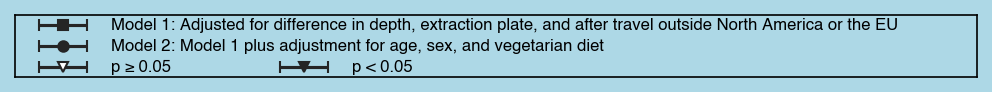

In [28]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6.5, 0.5), facecolor='lightblue')
def _plot_caption1(fig):
    """
    Helper function to make a legend
    """
    ax = fig.add_subplot(1,1,1, facecolor='None')
    ax.xaxis.set_tick_params(left=False, labelleft=False, right=False, 
                             labelright=False, labelsize=0, length=0)
    ax.yaxis.set_tick_params(left=False, labelleft=False, right=False, 
                             labelright=False, labelsize=0, length=0)
    ax.errorbar(x = [0.05], y=2, xerr=0.025, marker='s', capsize=3, color='#252525', markersize=5)
    ax.errorbar(x = [0.05], y=1, xerr=0.025, marker='o', capsize=3, color='#252525', markersize=5)
    ax.errorbar(x = [0.05], y=0, xerr=0.025, marker='v', capsize=3, color='#252525', markerfacecolor='w', markersize=5)
    ax.errorbar(x = [0.30], y=0, xerr=0.025, marker='v', capsize=3, color='#252525', markersize=5)
    
    ax.text(x=0.1, y=2, ha='left', va='center', size=8,
            s=('Model 1: Adjusted for difference in depth, extraction plate, and after travel outside North America or the EU'))
    ax.text(x=0.1, y=1, ha='left', va='center', size=8,
            s=('Model 2: Model 1 plus adjustment for age, sex, and vegetarian diet'))
    ax.text(x=0.1, y=0, ha='left', va='center', size=8, s=('p ≥ 0.05'))
    ax.text(x=0.35, y=0, ha='left', va='center', size=8, s=('p < 0.05'))
    ax.set_ylim(-0.5, 2.5)
    ax.set_xlim(0, 1)
_plot_caption1(fig)

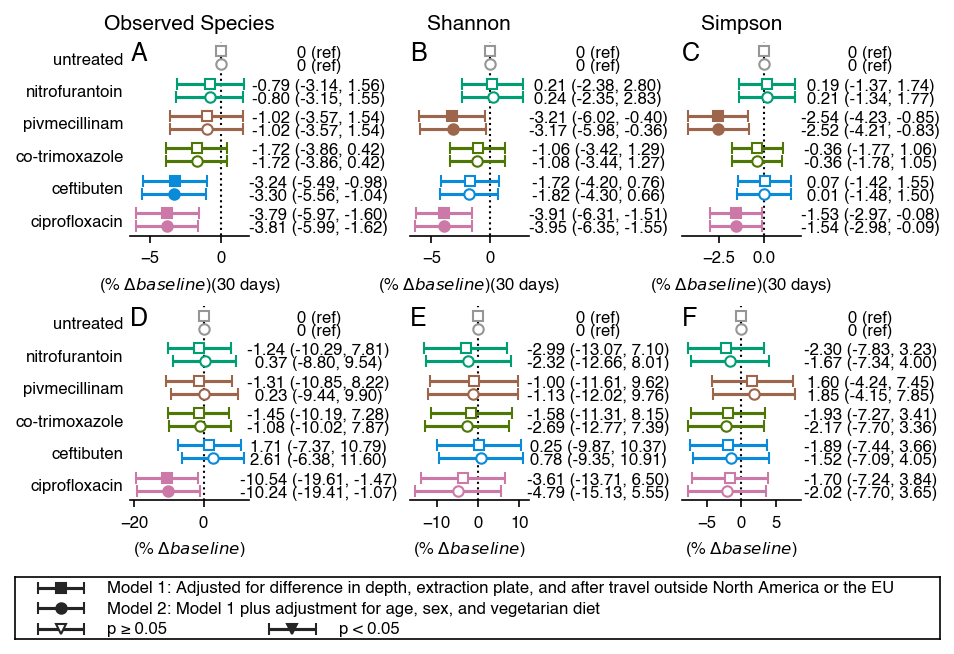

In [29]:
fig1 = plt.figure(dpi=150, constrained_layout=True, figsize=(6.25, 4.25))
fig1a, fig1b = fig1.subfigures(2, 1, height_ratios=[3.75, 0.5], facecolor='None')


_wrap_forest(fig1a, sub_re.reset_index())
_plot_caption1(fig1b)

**Figure S7.  The effect of antibiotic treatment on microbial alpha diversity with an without baseline participant characteristics.**
Alpha diversity was model using a -perturbation-recovery model, which has two parameters: (A-C) the rate of recovery and (D-F) the new steady state. Data was modeled using a random effects framework; model 1 (square) was adjusted for extraction plate, difference between baseline and sample depth, and whether the sample was collected after travel. Model 2 (circle) was adjusted for model 1 as well as the participant age, sex, and whether they consumed a vegetarian diet. Filled circles indicate a statistically significant (p < 0.05) effect. Data was analyzed for (A,D) Observed Species, (B,E) Shannon diversity, and (C,F) Simpson diversity, which place increasing emphasis on evenness.

## Random intercept vs Random Slope

In [30]:
sub_re_rs = fit_unt_params.copy().xs('model 2', level='model')
sub_re_rs.reset_index(level=['ref_value'], drop=True, inplace=True)
sub_re_rs.reset_index(inplace=True)

sub_re_rs['width'] = sub_re_rs['ci_hi'] - sub_re['params']
sub_re_rs['tidy'] = sub_re_rs.apply(
    lambda x: '{params:1.2f} ({ci_lo:1.2f}, {ci_hi:1.2f})'.format(**x), axis=1)
sub_re_rs['tidy'] = \
    sub_re_rs['tidy'].mask(sub_re_rs['abx_code'].isin(['0', 0]), '0 (ref)')
sub_re_rs['params'] = sub_re_rs['params'].mask(sub_re_rs['abx_code'].isin(['0', 0]), 0)
sub_re_rs['width'] = sub_re_rs['width'].mask(sub_re_rs['abx_code'].isin(['0', 0]), np.nan)
sub_re_rs['p_value'] = sub_re_rs['p_value'].mask(sub_re_rs['abx_code'].isin(['0', 0]), 1)


sub_re_rs['y'] = 5 - sub_re_rs['abx_code'].astype(int) + \
    (sub_re_rs['rs_slope'] * -2 + 1) * 0.2
sub_re_rs['color'] = sub_re_rs['abx_code'].replace(abx_colors)
sub_re_rs['facecolor'] = sub_re_rs['color'].mask(sub_re_rs['p_value'] >= 0.05, 'w')
sub_re_rs['marker'] = sub_re_rs['rs_slope'].replace({0: 's', 1: 'D'})



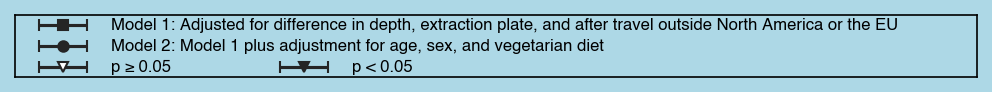

In [31]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6.5, 0.5), facecolor='lightblue')
def _plot_caption2(fig):
    """
    Helper function to make a legend
    """
    ax = fig.add_subplot(1,1,1, facecolor='None')
    ax.xaxis.set_tick_params(left=False, labelleft=False, right=False, 
                             labelright=False, labelsize=0, length=0)
    ax.yaxis.set_tick_params(left=False, labelleft=False, right=False, 
                             labelright=False, labelsize=0, length=0)
    ax.errorbar(x = [0.05], y=1, xerr=0.025, marker='s', capsize=3, color='#252525', markersize=5)
    ax.errorbar(x = [0.30], y=1, xerr=0.025, marker='D', capsize=3, color='#252525', markersize=5)
    ax.errorbar(x = [0.05], y=0, xerr=0.025, marker='v', capsize=3, color='#252525', markerfacecolor='w', markersize=5)
    ax.errorbar(x = [0.30], y=0, xerr=0.025, marker='v', capsize=3, color='#252525', markersize=5)
    
    ax.text(x=0.025, y=2, ha='left', va='center', size=8,
            s=('Adjusted for difference in depth, extraction plate, and after travel outside North America or the EU'))
    ax.text(x=0.1, y=1, ha='left', va='center', size=8, s=('Main model'))
    ax.text(x=0.35, y=1, ha='left', va='center', size=8, s=('With personal rate of recovery'))
    ax.text(x=0.1, y=0, ha='left', va='center', size=8, s=('p ≥ 0.05'))
    ax.text(x=0.35, y=0, ha='left', va='center', size=8, s=('p < 0.05'))
    ax.set_ylim(-0.5, 2.5)
    ax.set_xlim(0, 1)
_plot_caption1(fig)

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


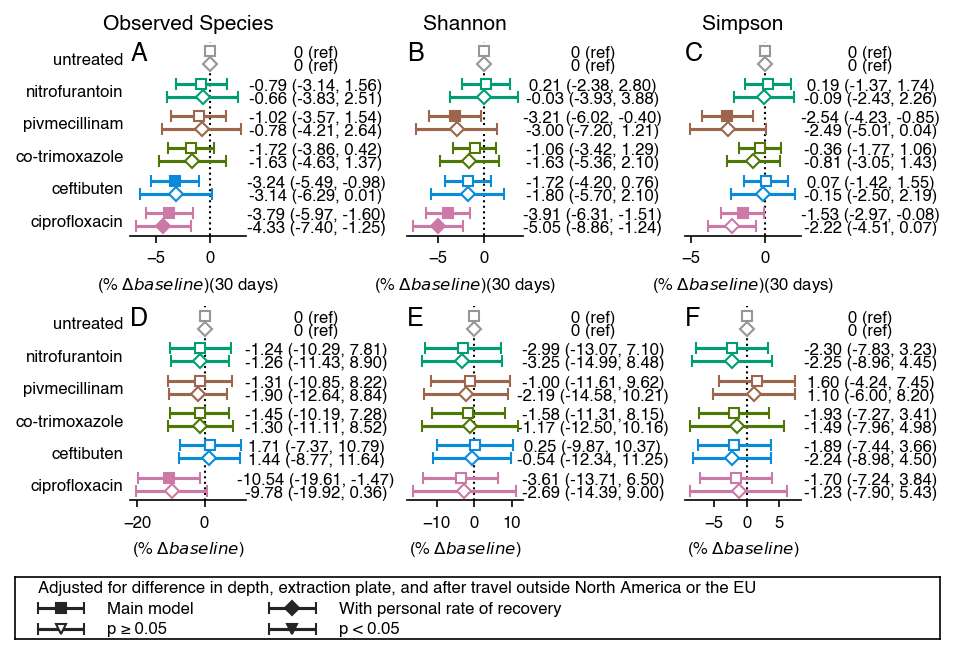

In [32]:
fig1 = plt.figure(dpi=150, constrained_layout=True, figsize=(6.25, 4.25))
fig1a, fig1b = fig1.subfigures(2, 1, height_ratios=[3.75, 0.5], facecolor='None')


_wrap_forest(fig1a, sub_re_rs)
_plot_caption2(fig1b)


fig1.savefig('output/figures/fig_s7_alpha_fit.png', dpi=600, facecolor='None')
fig1.savefig('output/figures/fig_s7_alpha_fit.pdf', dpi=600, facecolor='None')


**Figure S8. Individual effects on the change in alpha diversity in response to antibiotic treatment.** The effect of antibiotic treatment on the microbiome using a treatment/recovery model, which had two parameters: (A-C) the rate of recovery and (D-F) the new steady state. The data was modeled using a linear mixed effect model with a random intercept (square), allowing participants to recover to a new steady state or random intercept and random slope (diamond), allowing both a new steady state and an individual rate of recovery. Both models were adjusted for extraction plate, difference between baseline and sample depth, and whether the sample was collected after travel. Filled symbols indicate a statistically significant (p < 0.05) effect. Data was analyzed for (A,D) Observed Species, (B,E) Shannon diversity, and (C,F) Simpson diversity, which place increasing emphasis on evenness, indicating a larger change in abundance.

## Post-hoc summary

In [33]:
os.listdir('final-data/04.alpha-diveristy/post-hoc-fits')

['alpha_trace.tsv',
 'alpha_expanded_est.tsv',
 'alpha_expanded_contrasts.tsv',
 'alpha_strat_contrasts.tsv',
 'alpha_strat_est.tsv']

In [34]:
ph_res = pd.read_csv('final-data/04.alpha-diveristy/post-hoc-fits/alpha_expanded_contrasts.tsv',
                     sep='\t',
                     dtype=str)
ph_res.set_index(['metric', 'model', 'rs', 'kind', 'abx0', 'abx1'],
                 inplace=True)
ph_res = ph_res.astype(float)
ph_res['estimate'] = ph_res['estimate'] * -1
ph_res['width'] = ph_res['SE'] * scipy.stats.t.ppf(1 - 0.05 / 2, ph_res['df'] - 1)
ph_res['ci_lo'] = ph_res['estimate'] - ph_res['width']
ph_res['ci_hi'] = ph_res['estimate'] + ph_res['width']

In [35]:
emmeans_est = pd.read_csv('final-data/04.alpha-diveristy/post-hoc-fits/alpha_expanded_est.tsv',
                          sep='\t',
                          dtype=str)
emmeans_est.set_index(['metric', 'model', 'rs', 'kind', 'abx_code2'], inplace=True)
emmeans_est = emmeans_est.astype(float)
emmeans_est['tidy'] = emmeans_est[['beta', 'lower.CL', 'upper.CL']].apply(
    lambda x: '{0:1.2f} ({1:1.2f}, {2:1.2f})'.format(*x),
    axis=1)
emmeans_est2 = emmeans_est.xs('model2', level='model').xs('re', level='rs')

In [36]:
def _tidy_p(x):
    if x >= 0.01:
        return f'p={x:1.2f}'
    elif x >= 0.001:
        return f'p={x:1.3f}'
    else:
        return 'p=>0.001'


In [37]:
em_compare = ph_res.copy().xs('model2', level='model')
em_compare = em_compare.xs('re', level='rs')
em_compare.reset_index('abx1', inplace=True)
em_compare['abx0_est'] = emmeans_est2.loc[em_compare.index, 'tidy']
em_compare.reset_index('abx0', inplace=True)
em_compare.set_index('abx1',append=True, inplace=True)
em_compare['abx1_est'] = emmeans_est2.loc[em_compare.index, 'tidy']
em_compare.reset_index(inplace=True)
em_compare.set_index(['kind', 'metric', 'abx0', 'abx1'], inplace=True)
em_compare['comp_tidy'] = em_compare[['estimate', 'ci_lo', 'ci_hi']].apply(
    lambda x: '{0:1.2f} ({1:1.2f}, {2:1.2f})'.format(*x), axis=1)
em_compare['comp_p'] = em_compare['p.value'].apply(_tidy_p)

em_compare = em_compare[['abx0_est', 'abx1_est', 'comp_tidy', 'comp_p']].copy()
em_compare.rename(abx_names, level='abx0', inplace=True)
em_compare.rename(abx_names, level='abx1', inplace=True)
em_compare.rename({'observed_features': 'Observed Species',
                   'shannon': 'Shannon diversity',
                   'simpson': 'Simpson diversity'},
                  level='metric',
                  inplace=True)


In [38]:
HTML(em_compare.to_html())

In [40]:
os.makedirs('output/tables', exist_ok=True)
em_compare.to_csv('output/tables/table_s3_alpha_posthoc.tsv',
                  sep='\t')